In [ ]:
import os

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

In [ ]:
from google.colab import files
uploaded = files.upload()
df=pd.read_excel("df_final.xlsx")
df.head()

Saving df_final.xlsx to df_final.xlsx


,Student_ID,Academic Year,APPLIED MECHANICS,COMPUTER SKILLS,CONSTRUCTION MATERIALS TECHNOLOGY,ENGINEERING CHEMISTRY,ENGINEERING DRAWING 1,ENGINEERING MATHEMATICS 1,ENGINEERING PHYSICS,PROFESSIONAL AND TECHNICAL COMMUNICATION,...,Language Name,Ethnic Group Name,Previous Activity Desc,Matric Type,Age_At_Enrolment,Bursary Type,Funded,Residence_Status,At_Risk_Status,Secondary_School_Quintile
0,ebad61ae15967effac440603214e2e829bb29399e52236...,2022,80,76,67,77,67,62,50,58,...,ISIZULU,AFRICAN,UNEMPLOYED,B,19,NSFAS,Yes,Yes,No,3
1,f521b30f9daaa32d07004bfe337461cbe32083db1a4c4f...,2022,68,42,62,72,65,66,55,63,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,Yes,2
2,a39ac7e2e46a3c504ea680c833542b44509590f9566861...,2022,50,59,63,69,73,51,50,62,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,No,5
3,32d8a74e94211a616b9c701f62ebf8ef4a90162ab430a6...,2022,56,62,62,75,55,50,53,57,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,Yes,1
4,d5aa2443cbcb70dfffa1a66fcbcf4bca0953a2d8d55e39...,2022,64,66,71,78,53,69,56,59,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,No,3


# Data Cleaning

In [ ]:
# Display a concise summary of the DataFrame
# This includes the index dtype and columns, non-null values, and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330 entries, 0 to 329
Data columns (total 23 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   Student_ID                                330 non-null    object
 1   Academic Year                             330 non-null    int64 
 2   APPLIED MECHANICS                         330 non-null    int64 
 3   COMPUTER SKILLS                           330 non-null    int64 
 4   CONSTRUCTION MATERIALS TECHNOLOGY         330 non-null    int64 
 5   ENGINEERING CHEMISTRY                     330 non-null    int64 
 6   ENGINEERING DRAWING 1                     330 non-null    int64 
 7   ENGINEERING MATHEMATICS 1                 330 non-null    int64 
 8   ENGINEERING PHYSICS                       330 non-null    int64 
 9   PROFESSIONAL AND TECHNICAL COMMUNICATION  330 non-null    int64 
 10  SURVEYING                                 330 non-

In [ ]:
df.describe()

,Academic Year,APPLIED MECHANICS,COMPUTER SKILLS,CONSTRUCTION MATERIALS TECHNOLOGY,ENGINEERING CHEMISTRY,ENGINEERING DRAWING 1,ENGINEERING MATHEMATICS 1,ENGINEERING PHYSICS,PROFESSIONAL AND TECHNICAL COMMUNICATION,SURVEYING,THEORY OF STRUCTURES,Age_At_Enrolment,Secondary_School_Quintile
count,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000,330.000000
mean,2023.687879,65.721212,70.287879,66.175758,67.103030,61.275758,61.227273,58.127273,74.890909,62.563636,56.206061,19.848485,3.142424
std,1.041468,12.301970,12.449979,9.891172,9.428421,12.053314,12.481227,8.043320,9.448641,13.288838,15.022373,1.615299,1.495999
min,2022.000000,20.000000,2.000000,0.000000,30.000000,10.000000,18.000000,18.000000,19.000000,12.000000,0.000000,17.000000,1.000000
25%,2023.000000,56.000000,65.000000,60.000000,62.000000,54.000000,53.000000,53.000000,70.000000,54.000000,50.000000,19.000000,2.000000
50%,2024.000000,65.000000,71.000000,66.000000,68.000000,61.000000,62.000000,58.000000,76.000000,63.000000,56.000000,19.000000,3.000000
75%,2025.000000,73.000000,78.000000,72.000000,72.000000,69.000000,69.000000,63.000000,81.000000,72.000000,65.000000,20.000000,5.000000
max,2025.000000,99.000000,96.000000,92.000000,94.000000,89.000000,97.000000,82.000000,95.000000,94.000000,94.000000,28.000000,5.000000


In [ ]:
# Each row should be exactly one student
print('Rows:', len(df), '| Columns:', df.shape[1])
print('Duplicated Student_ID:', df['Student_ID'].duplicated().sum())
print('Fully duplicated rows:', df.duplicated().sum())

Rows: 330 | Columns: 23
Duplicated Student_ID: 0
Fully duplicated rows: 0


In [ ]:
# DROP IRRELEVANT COLUMNS
# Student_ID is an anonymised hash. It identifies a row but carries no information, so it is removed.
df1 = df.drop(columns=['Student_ID'])
df1.columns = df1.columns.astype(str).str.strip()
df1.head()

,Academic Year,APPLIED MECHANICS,COMPUTER SKILLS,CONSTRUCTION MATERIALS TECHNOLOGY,ENGINEERING CHEMISTRY,ENGINEERING DRAWING 1,ENGINEERING MATHEMATICS 1,ENGINEERING PHYSICS,PROFESSIONAL AND TECHNICAL COMMUNICATION,SURVEYING,...,Language Name,Ethnic Group Name,Previous Activity Desc,Matric Type,Age_At_Enrolment,Bursary Type,Funded,Residence_Status,At_Risk_Status,Secondary_School_Quintile
0,2022,80,76,67,77,67,62,50,58,66,...,ISIZULU,AFRICAN,UNEMPLOYED,B,19,NSFAS,Yes,Yes,No,3
1,2022,68,42,62,72,65,66,55,63,63,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,Yes,2
2,2022,50,59,63,69,73,51,50,62,67,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,No,5
3,2022,56,62,62,75,55,50,53,57,56,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,Yes,1
4,2022,64,66,71,78,53,69,56,59,69,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,No,3


In [ ]:
# RENAME columns to short, consistent names
rename_map = {
    # subjects
    'APPLIED MECHANICS': 'Applied Mechanics',
    'COMPUTER SKILLS': 'Computer Skills',
    'CONSTRUCTION MATERIALS TECHNOLOGY': 'Construction Materials',
    'ENGINEERING CHEMISTRY': 'Engineering Chemistry',
    'ENGINEERING DRAWING 1': 'Engineering Drawing 1',
    'ENGINEERING MATHEMATICS 1': 'Engineering Mathematics 1',
    'ENGINEERING PHYSICS': 'Engineering Physics',
    'PROFESSIONAL AND TECHNICAL COMMUNICATION': 'Professional Communication',
    'SURVEYING': 'Surveying',
    'THEORY OF STRUCTURES': 'Theory of Structures',
    # student characteristics
    'Language Name': 'Home Language',
    'Ethnic Group Name': 'Ethnic Group',
    'Previous Activity Desc': 'Previous Activity',
    'Age_At_Enrolment': 'Age at Enrolment',
    'Residence_Status': 'In Residence',
    'Secondary_School_Quintile': 'School Quintile',
    # target
    'At_Risk_Status': 'At Risk',
}
df1 = df1.rename(columns=rename_map)

subject_cols = ['Applied Mechanics', 'Computer Skills', 'Construction Materials', 'Engineering Chemistry',
                'Engineering Drawing 1', 'Engineering Mathematics 1', 'Engineering Physics',
                'Professional Communication', 'Surveying', 'Theory of Structures']
df1.columns.tolist()

['Academic Year',
 'Applied Mechanics',
 'Computer Skills',
 'Construction Materials',
 'Engineering Chemistry',
 'Engineering Drawing 1',
 'Engineering Mathematics 1',
 'Engineering Physics',
 'Professional Communication',
 'Surveying',
 'Theory of Structures',
 'Gender',
 'Home Language',
 'Ethnic Group',
 'Previous Activity',
 'Matric Type',
 'Age at Enrolment',
 'Bursary Type',
 'Funded',
 'In Residence',
 'At Risk',
 'School Quintile']

Handling missing values and feature engineering.

In [ ]:
# The study keeps only students with a complete set of the ten first-year subject marks
df1[subject_cols] = df1[subject_cols].apply(pd.to_numeric, errors='coerce')
incomplete = df1[subject_cols].isnull().any(axis=1)
print(f'Students with a missing subject mark (removed): {incomplete.sum()}')

df1 = df1.loc[~incomplete].reset_index(drop=True)
print(f'Students kept: {len(df1)}')

Students with a missing subject mark (removed): 0
Students kept: 330


In [ ]:
# Make the labels consistent: Yes/No columns, readable gender labels
yes_no = {1: 'Yes', 0: 'No', 'Yes': 'Yes', 'No': 'No', 'Y': 'Yes', 'N': 'No'}
for col in ['Funded', 'In Residence', 'At Risk']:
    df1[col] = df1[col].map(yes_no)

assert df1['At Risk'].notna().all(), 'At Risk has values other than Yes/No'

df1['Gender'] = df1['Gender'].replace({'F': 'Female', 'M': 'Male'})
df1[['Gender', 'Funded', 'In Residence', 'At Risk']].describe()

,Gender,Funded,In Residence,At Risk
count,330,330,330,330
unique,2,2,2,2
top,Male,Yes,Yes,No
freq,180,260,173,209


In [ ]:
# Missing categorical values are kept as their own category instead of being dropped
cat_to_impute = ['Gender', 'Home Language', 'Ethnic Group', 'Previous Activity', 'Matric Type',
                 'Bursary Type', 'Funded', 'In Residence']
df1[cat_to_impute] = df1[cat_to_impute].fillna('Not Specified')

# School Quintile is a category (1 = least resourced school, 5 = best resourced); missing or invalid -> 'Others'
quintile = pd.to_numeric(df1['School Quintile'], errors='coerce')
df1['School Quintile'] = quintile.where(quintile.between(1, 5)).map(lambda v: 'Others' if pd.isna(v) else str(int(v)))
df1['School Quintile'].value_counts()

,count
School Quintile,
5,101
3,70
2,67
1,60
4,32


Outlier check

In [ ]:
outlier_rows = []
for col in subject_cols + ['Age at Enrolment']:
    s = df1[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({'Variable': col, 'Lower fence': lower, 'Upper fence': upper,
                         'Outliers': n_out, '% of students': 100 * n_out / len(s)})

pd.DataFrame(outlier_rows).round(2)

,Variable,Lower fence,Upper fence,Outliers,% of students
0,Applied Mechanics,30.5,98.5,3,0.91
1,Computer Skills,45.5,97.5,14,4.24
2,Construction Materials,42.0,90.0,4,1.21
3,Engineering Chemistry,47.0,87.0,13,3.94
4,Engineering Drawing 1,31.5,91.5,5,1.52
5,Engineering Mathematics 1,29.0,93.0,6,1.82
6,Engineering Physics,38.0,78.0,6,1.82
7,Professional Communication,53.5,97.5,7,2.12
8,Surveying,27.0,99.0,3,0.91
9,Theory of Structures,27.5,87.5,14,4.24


In [ ]:
# Export the cleaned DataFrame to a CSV file (optional)
#df1.to_csv('at_risk_students_clean.csv', index=False)
df1.head()

,Academic Year,Applied Mechanics,Computer Skills,Construction Materials,Engineering Chemistry,Engineering Drawing 1,Engineering Mathematics 1,Engineering Physics,Professional Communication,Surveying,...,Home Language,Ethnic Group,Previous Activity,Matric Type,Age at Enrolment,Bursary Type,Funded,In Residence,At Risk,School Quintile
0,2022,80,76,67,77,67,62,50,58,66,...,ISIZULU,AFRICAN,UNEMPLOYED,B,19,NSFAS,Yes,Yes,No,3
1,2022,68,42,62,72,65,66,55,63,63,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,Yes,2
2,2022,50,59,63,69,73,51,50,62,67,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,No,5
3,2022,56,62,62,75,55,50,53,57,56,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,Yes,1
4,2022,64,66,71,78,53,69,56,59,69,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,No,3


# Data Analysis

In [ ]:
data_for_plots = df1          # dataframe used by the plotting functions
TOP_N = 10                    # max categories shown for text columns
sns.set_style('whitegrid')

# Numeric target used by the at-risk-rate charts and the tests further down
df1['At_Risk_Numeric'] = df1['At Risk'].map({'Yes': 1, 'No': 0})

# Natural order for categories that are not alphabetical or numeric
COLUMN_ORDER = {
    'School Quintile': ['1', '2', '3', '4', '5', 'Others'],
    'Age Group': ['18 or younger', '19', '20', '21 or older', 'Not Specified'],
}


def fmt_label(v):
    """Readable label: 'Missing' for NaN, no trailing .0 for whole numbers."""
    if pd.isna(v):
        return 'Missing'
    if isinstance(v, (float, np.floating)) and float(v).is_integer():
        return str(int(v))
    return str(v)


def add_bar_labels(ax, fmt='{:,.0f}', fontsize=8, pad=2):
    """Write the value on top of every (visible) bar in the axes."""
    for p in ax.patches:
        h = p.get_height()
        if pd.isna(h) or p.get_width() == 0:      # skip empty / placeholder bars
            continue
        ax.annotate(fmt.format(h),
                    (p.get_x() + p.get_width() / 2, h),
                    ha='center', va='bottom' if h >= 0 else 'top', fontsize=fontsize,
                    xytext=(0, pad if h >= 0 else -pad), textcoords='offset points')
    ax.margins(y=0.12)                            # head-room so labels are not clipped


def _rotate_if_needed(labels, many=6, long=8):
    """Rotate x labels when there are many or they are long."""
    first_lines = [str(l).split('\n')[0] for l in labels]
    rotate = len(labels) > many or max(len(l) for l in first_lines) > long
    plt.xticks(rotation=35 if rotate else 0, ha='right' if rotate else 'center', fontsize=8)


def _order_for(col, df):
    """Category order: defined order, natural order for numbers, by frequency for text."""
    s = df[col].dropna()
    if col in COLUMN_ORDER:
        present = set(s.unique())
        return [c for c in COLUMN_ORDER[col] if c in present]
    if pd.api.types.is_numeric_dtype(s):
        return sorted(s.unique())
    return list(s.value_counts().index)


# 1) Vertical count plot with the count on top of each bar
def plot_categorical(col, df=None, top_n=None, palette='viridis', title=None):
    df = data_for_plots if df is None else df
    top_n = TOP_N if top_n is None else top_n
    if col not in df.columns:
        print(f"Column '{col}' not found."); return

    order = _order_for(col, df)
    n_unique = len(order)
    truncated = (col not in COLUMN_ORDER) and (not pd.api.types.is_numeric_dtype(df[col])) and n_unique > top_n
    if truncated:
        order = order[:top_n]
    counts = df[col].value_counts().reindex(order)
    labels = [fmt_label(v) for v in order]

    plt.figure(figsize=(max(6.5, 0.65 * len(labels) + 2), 4.5))
    ax = sns.barplot(x=labels, y=counts.values, hue=labels, palette=palette, legend=False)
    add_bar_labels(ax)

    ttl = title or f'{col} Counts'
    if truncated:
        ttl += f' (Top {top_n} of {n_unique})'
    plt.title(ttl, fontsize=11, fontweight='bold')
    plt.xlabel(col, fontsize=9)
    plt.ylabel('Count', fontsize=9)
    _rotate_if_needed(labels)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()

# 2) Pie chart showing the share (%) and count of each category
def plot_pie(col, df=None, top_n=6, palette='Set2', title=None):
    df = data_for_plots if df is None else df
    if col not in df.columns:
        print(f"Column '{col}' not found."); return

    order = _order_for(col, df)
    counts = df[col].value_counts().reindex(order)
    if len(counts) > top_n and col not in COLUMN_ORDER:   # group the tail into 'Other'
        counts = counts.sort_values(ascending=False)
        counts = pd.concat([counts.head(top_n - 1),
                            pd.Series({'Other': counts.iloc[top_n - 1:].sum()})])
    labels = [fmt_label(v) for v in counts.index]
    total = counts.sum()

    fig, ax = plt.subplots(figsize=(6, 4.5))
    wedges, _, autotexts = ax.pie(
        counts.values, colors=sns.color_palette(palette, len(counts)),
        startangle=90, counterclock=False,
        autopct=lambda p: f'{p:.1f}%\n({int(round(p * total / 100))})' if p >= 3 else '',
        pctdistance=0.7, wedgeprops=dict(edgecolor='white', linewidth=1.5),
        textprops=dict(fontsize=8))
    ax.legend(wedges, labels, title=col, loc='center left',
              bbox_to_anchor=(1.0, 0.5), fontsize=8, title_fontsize=9, frameon=False)
    ax.set_title(title or f'{col} (% of students)', fontsize=11, fontweight='bold')
    ax.axis('equal')
    plt.tight_layout()
    plt.show()

# 3) At-risk rate by a feature, % on top of each bar, group size (n) under each label
def plot_rate_by(col, df=None, target='At_Risk_Numeric', palette='viridis', title=None):
    df = data_for_plots if df is None else df
    if col not in df.columns:
        print(f"Column '{col}' not found."); return

    order = _order_for(col, df)
    g = df.groupby(col)[target].agg(['mean', 'size']).reindex(order)
    labels = [f'{fmt_label(v)}\n(n={int(n)})' for v, n in zip(g.index, g['size'])]

    plt.figure(figsize=(max(6.5, 0.65 * len(labels) + 2), 4.5))
    ax = sns.barplot(x=labels, y=g['mean'].values, hue=labels, palette=palette, legend=False)
    add_bar_labels(ax, fmt='{:.1%}')
    ax.axhline(df[target].mean(), ls='--', color='grey', lw=1, label=f'Overall rate ({df[target].mean():.1%})')

    plt.title(title or f'At-Risk Rate by {col}', fontsize=11, fontweight='bold')
    plt.xlabel(col, fontsize=9)
    plt.ylabel('At-Risk Rate', fontsize=9)
    plt.ylim(0, 1.0)
    plt.legend(fontsize=8, loc='upper right')
    _rotate_if_needed(labels)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()

# 4) Grouped count plot with counts on the bars
def plot_grouped_counts(x, hue, df=None, palette='viridis', title=None, legend_title=None):
    df = data_for_plots if df is None else df
    if x not in df.columns or hue not in df.columns:
        print(f"Column '{x}' or '{hue}' not found."); return

    order = _order_for(x, df)
    hue_order = _order_for(hue, df)
    plt.figure(figsize=(max(5.5, 1.1 * len(order) + 2.5), 4.5))
    ax = sns.countplot(data=df, x=x, hue=hue, order=order, hue_order=hue_order, palette=palette)
    add_bar_labels(ax)

    plt.title(title or f'{hue} by {x}', fontsize=11, fontweight='bold')
    plt.xlabel(x, fontsize=9)
    plt.ylabel('Count', fontsize=9)
    _rotate_if_needed([fmt_label(v) for v in order])
    plt.yticks(fontsize=8)
    plt.legend(title=legend_title or hue, fontsize=8, title_fontsize=9)
    plt.tight_layout()
    plt.show()


# 5) Boxplot of a numeric column (default Average Mark) by a category
def plot_box_by(col, y='Average Mark', df=None, palette='Set2', title=None):
    df = data_for_plots if df is None else df
    if col not in df.columns or y not in df.columns:
        print(f"Column '{col}' or '{y}' not found."); return
    order = _order_for(col, df)
    plt.figure(figsize=(max(6.5, 0.9 * len(order) + 2.5), 4.5))
    sns.boxplot(data=df, x=col, y=y, order=order, hue=col, palette=palette, legend=False)
    plt.title(title or f'{y} by {col}', fontsize=11, fontweight='bold')
    plt.xlabel(col, fontsize=9)
    plt.ylabel(y, fontsize=9)
    _rotate_if_needed([fmt_label(v) for v in order])
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()

## Explore the target variable

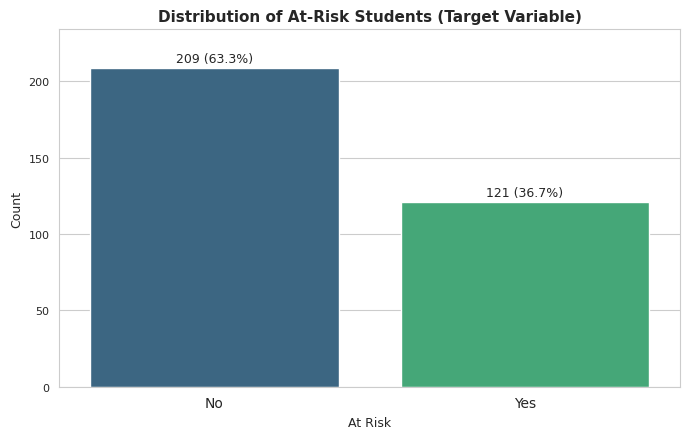

In [ ]:
# Calculate distribution and percentages
counts = df1['At Risk'].value_counts()
percentages = df1['At Risk'].value_counts(normalize=True) * 100
order = ['No', 'Yes']

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=order, y=[counts[o] for o in order], hue=order, palette='viridis', legend=False)

# Annotate each bar with both count and percentage
total = counts.sum()
for p in ax.patches:
    h = p.get_height()
    if pd.isna(h) or p.get_width() == 0:
        continue
    pct = (h / total) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, h),
                ha='center', va='bottom', fontsize=9,
                xytext=(0, 2), textcoords='offset points')

ax.margins(y=0.12)
plt.title('Distribution of At-Risk Students (Target Variable)', fontsize=11, fontweight='bold')
plt.xlabel('At Risk', fontsize=9)
plt.ylabel('Count', fontsize=9)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# Class balance check
counts = df1['At Risk'].value_counts()
percentages = df1['At Risk'].value_counts(normalize=True) * 100
for idx in counts.index:
    print(f"{idx}: {counts[idx]} ({percentages[idx]:.2f}%)")

No: 209 (63.33%)
Yes: 121 (36.67%)


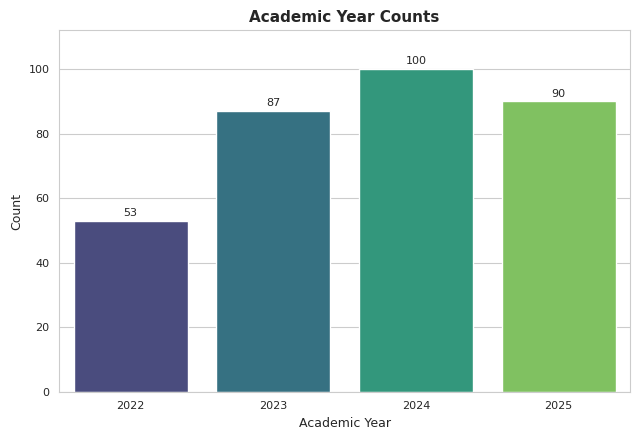

In [ ]:
# Academic Year: bar chart
plot_categorical('Academic Year')

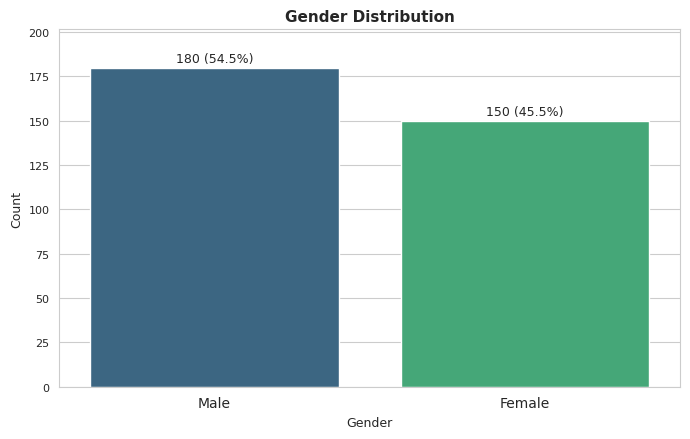

In [ ]:
# Gender: bar chart with absolute counts and percentages
counts = df1['Gender'].value_counts()
order = ['Male', 'Female']

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=order, y=[counts[o] for o in order], hue=order, palette='viridis', legend=False)

# Annotate each bar with both count and percentage
total = counts.sum()
for p in ax.patches:
    h = p.get_height()
    if pd.isna(h) or p.get_width() == 0:
        continue
    pct = (h / total) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, h),
                ha='center', va='bottom', fontsize=9,
                xytext=(0, 2), textcoords='offset points')

ax.margins(y=0.12)
plt.title('Gender Distribution', fontsize=11, fontweight='bold')
plt.xlabel('Gender', fontsize=9)
plt.ylabel('Count', fontsize=9)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

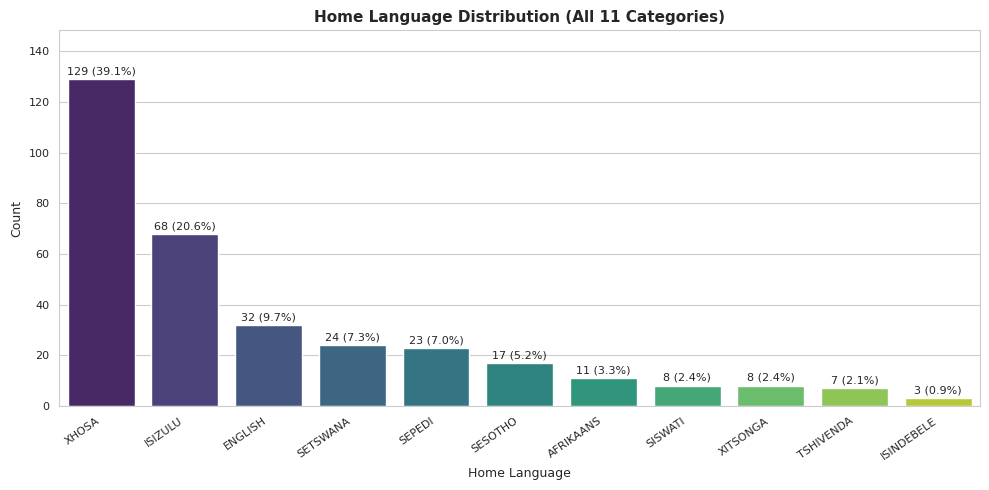

In [ ]:
# Home Language: bar chart showing all 11 categories with counts and percentages
counts = df1['Home Language'].value_counts()
total = counts.sum()
order = counts.index.tolist()

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=order, y=counts.values, hue=order, palette='viridis', legend=False)

# Annotate each bar with both count and percentage
for p in ax.patches:
    h = p.get_height()
    if pd.isna(h) or p.get_width() == 0:
        continue
    pct = (h / total) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, h),
                ha='center', va='bottom', fontsize=8,
                xytext=(0, 2), textcoords='offset points')

ax.margins(y=0.15)
plt.title('Home Language Distribution (All 11 Categories)', fontsize=11, fontweight='bold')
plt.xlabel('Home Language', fontsize=9)
plt.ylabel('Count', fontsize=9)
plt.xticks(rotation=35, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

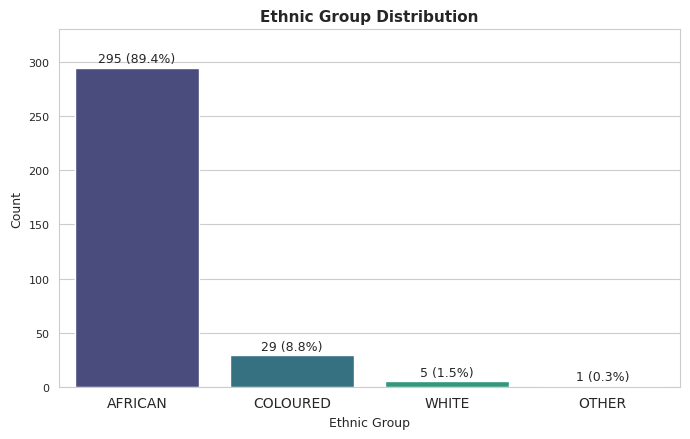

In [ ]:
# Ethnic Group: bar chart with absolute counts and percentages
counts = df1['Ethnic Group'].value_counts()
total = counts.sum()
order = counts.index.tolist()

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=order, y=counts.values, hue=order, palette='viridis', legend=False)

# Annotate each bar with both count and percentage
for p in ax.patches:
    h = p.get_height()
    if pd.isna(h) or p.get_width() == 0:
        continue
    pct = (h / total) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, h),
                ha='center', va='bottom', fontsize=9,
                xytext=(0, 2), textcoords='offset points')

ax.margins(y=0.12)
plt.title('Ethnic Group Distribution', fontsize=11, fontweight='bold')
plt.xlabel('Ethnic Group', fontsize=9)
plt.ylabel('Count', fontsize=9)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

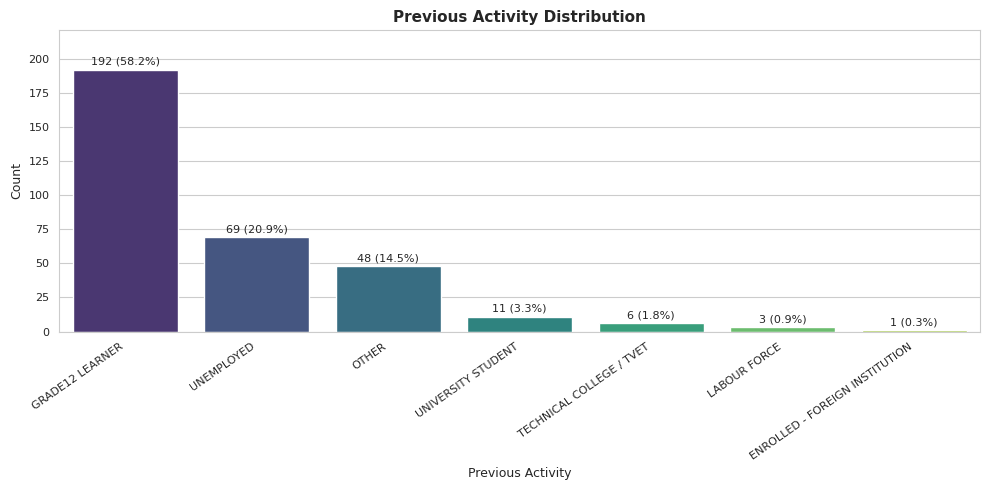

In [ ]:
# Previous Activity: bar chart with absolute counts and percentages
counts = df1['Previous Activity'].value_counts()
total = counts.sum()
order = counts.index.tolist()

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=order, y=counts.values, hue=order, palette='viridis', legend=False)

# Annotate each bar with both count and percentage
for p in ax.patches:
    h = p.get_height()
    if pd.isna(h) or p.get_width() == 0:
        continue
    pct = (h / total) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, h),
                ha='center', va='bottom', fontsize=8,
                xytext=(0, 2), textcoords='offset points')

ax.margins(y=0.15)
plt.title('Previous Activity Distribution', fontsize=11, fontweight='bold')
plt.xlabel('Previous Activity', fontsize=9)
plt.ylabel('Count', fontsize=9)
plt.xticks(rotation=35, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

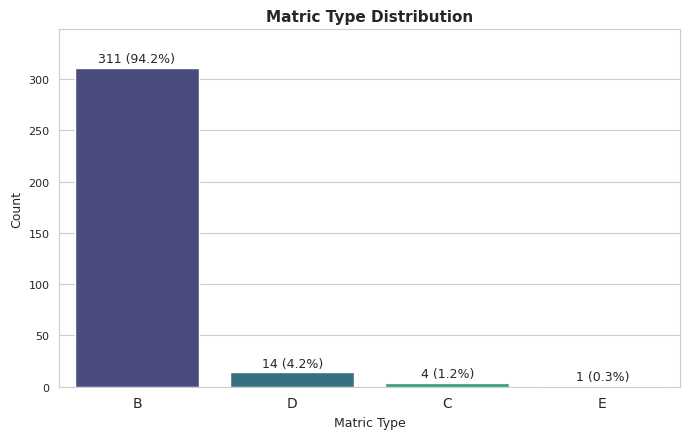

In [ ]:
# Matric Type: bar chart with absolute counts and percentages
counts = df1['Matric Type'].value_counts()
total = counts.sum()
order = counts.index.tolist()

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=order, y=counts.values, hue=order, palette='viridis', legend=False)

# Annotate each bar with both count and percentage
for p in ax.patches:
    h = p.get_height()
    if pd.isna(h) or p.get_width() == 0:
        continue
    pct = (h / total) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, h),
                ha='center', va='bottom', fontsize=9,
                xytext=(0, 2), textcoords='offset points')

ax.margins(y=0.12)
plt.title('Matric Type Distribution', fontsize=11, fontweight='bold')
plt.xlabel('Matric Type', fontsize=9)
plt.ylabel('Count', fontsize=9)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

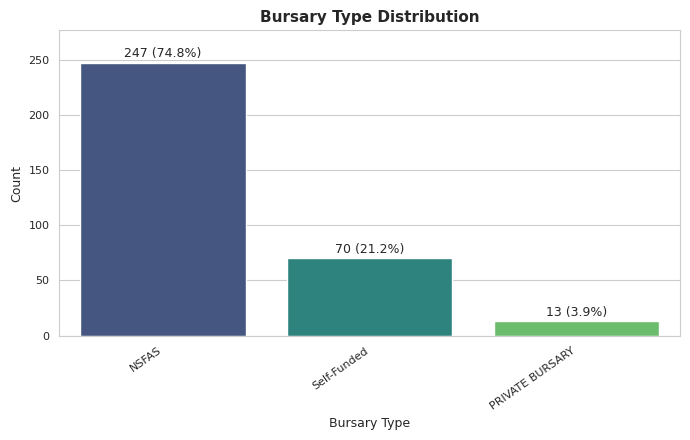

In [ ]:
# Bursary Type: bar chart with absolute counts and percentages
counts = df1['Bursary Type'].value_counts()
total = counts.sum()
order = counts.index.tolist()

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=order, y=counts.values, hue=order, palette='viridis', legend=False)

# Annotate each bar with both count and percentage
for p in ax.patches:
    h = p.get_height()
    if pd.isna(h) or p.get_width() == 0:
        continue
    pct = (h / total) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, h),
                ha='center', va='bottom', fontsize=9,
                xytext=(0, 2), textcoords='offset points')

ax.margins(y=0.12)
plt.title('Bursary Type Distribution', fontsize=11, fontweight='bold')
plt.xlabel('Bursary Type', fontsize=9)
plt.ylabel('Count', fontsize=9)
plt.xticks(rotation=35, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

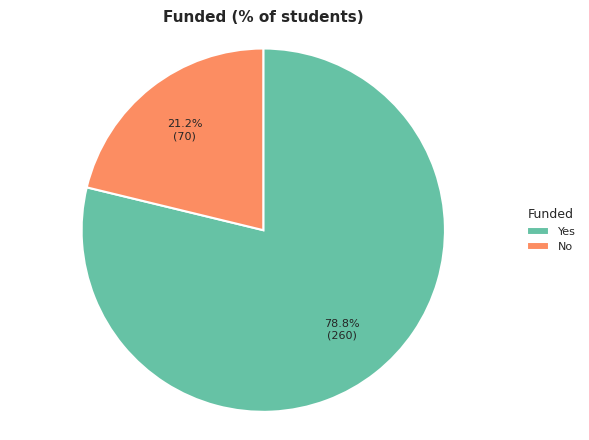

In [ ]:
# Funded: pie chart
plot_pie('Funded')

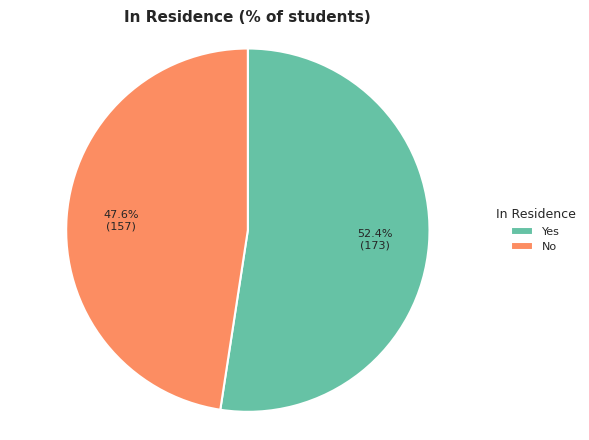

In [ ]:
# In Residence: pie chart
plot_pie('In Residence')

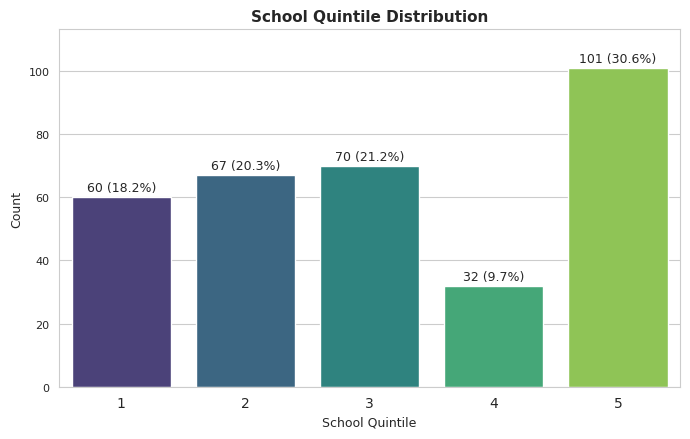

In [ ]:
# School Quintile: bar chart with absolute counts and percentages
counts = df1['School Quintile'].value_counts()
total = counts.sum()
order = ['1', '2', '3', '4', '5']
if 'Others' in counts.index:
    order.append('Others')

present_order = [o for o in order if o in counts.index]

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=present_order, y=[counts[o] for o in present_order], hue=present_order, palette='viridis', legend=False)

# Annotate each bar with both count and percentage
for p in ax.patches:
    h = p.get_height()
    if pd.isna(h) or p.get_width() == 0:
        continue
    pct = (h / total) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, h),
                ha='center', va='bottom', fontsize=9,
                xytext=(0, 2), textcoords='offset points')

ax.margins(y=0.12)
plt.title('School Quintile Distribution', fontsize=11, fontweight='bold')
plt.xlabel('School Quintile', fontsize=9)
plt.ylabel('Count', fontsize=9)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

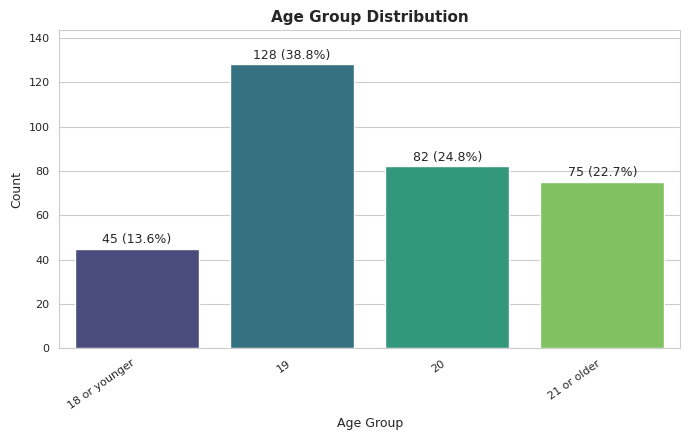

In [ ]:
# Age Group: Define the column first, then plot bar chart with absolute counts and percentages
bins = [0, 18, 19, 20, 100]
labels = ['18 or younger', '19', '20', '21 or older']
df1['Age Group'] = pd.cut(df1['Age at Enrolment'], bins=bins, labels=labels)

counts = df1['Age Group'].value_counts()
total = counts.sum()
order = ['18 or younger', '19', '20', '21 or older']
present_order = [o for o in order if o in counts.index]

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=present_order, y=[counts[o] for o in present_order], hue=present_order, palette='viridis', legend=False)

# Annotate each bar with both count and percentage
for p in ax.patches:
    h = p.get_height()
    if pd.isna(h) or p.get_width() == 0:
        continue
    pct = (h / total) * 100
    ax.annotate(f'{int(h)} ({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, h),
                ha='center', va='bottom', fontsize=9,
                xytext=(0, 2), textcoords='offset points')

ax.margins(y=0.12)
plt.title('Age Group Distribution', fontsize=11, fontweight='bold')
plt.xlabel('Age Group', fontsize=9)
plt.ylabel('Count', fontsize=9)
plt.xticks(rotation=35, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

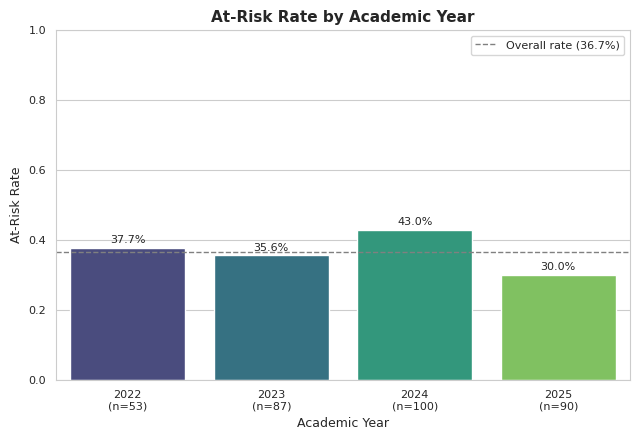

In [ ]:
# At-Risk Rate by Academic Year
plot_rate_by('Academic Year', title='At-Risk Rate by Academic Year')

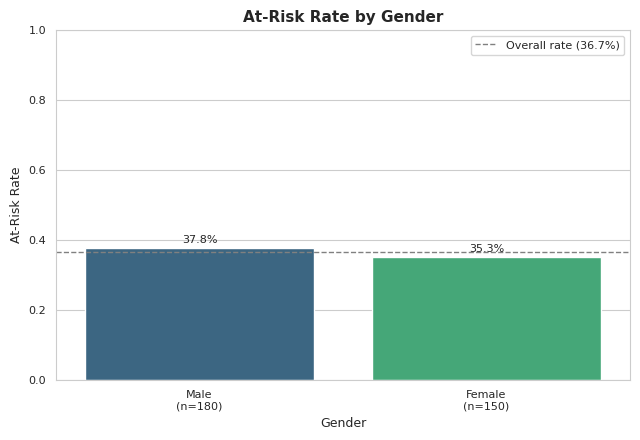

In [ ]:
# At-Risk Rate by Gender
plot_rate_by('Gender', title='At-Risk Rate by Gender')

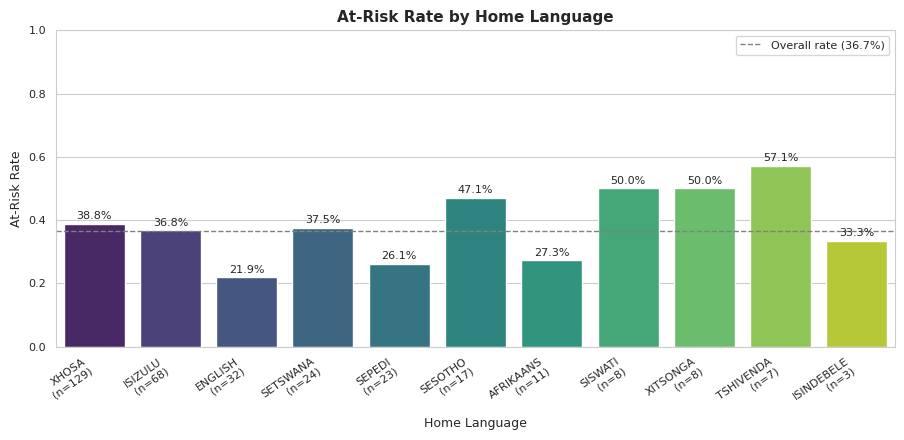

In [ ]:
# At-Risk Rate by Home Language
plot_rate_by('Home Language', title='At-Risk Rate by Home Language')

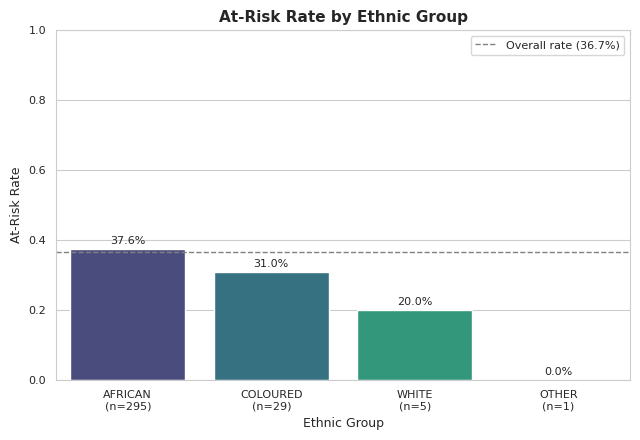

In [ ]:
# At-Risk Rate by Ethnic Group
plot_rate_by('Ethnic Group', title='At-Risk Rate by Ethnic Group')

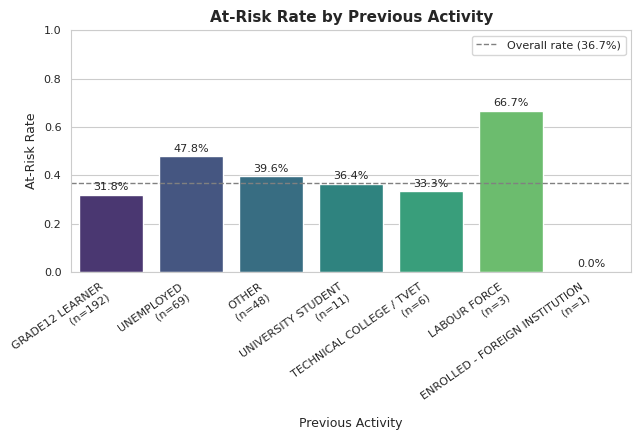

In [ ]:
# At-Risk Rate by Previous Activity
plot_rate_by('Previous Activity', title='At-Risk Rate by Previous Activity')

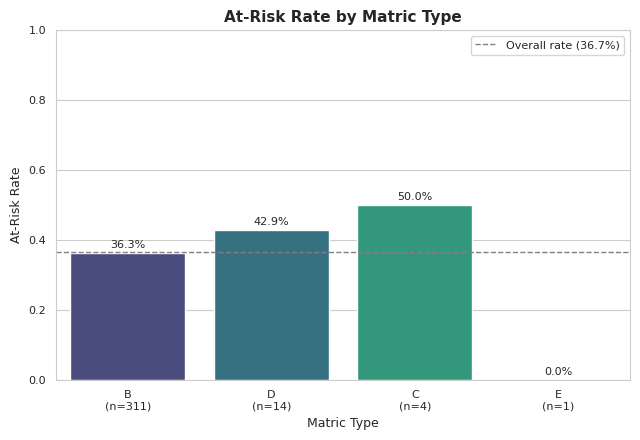

In [ ]:
# At-Risk Rate by Matric Type
plot_rate_by('Matric Type', title='At-Risk Rate by Matric Type')

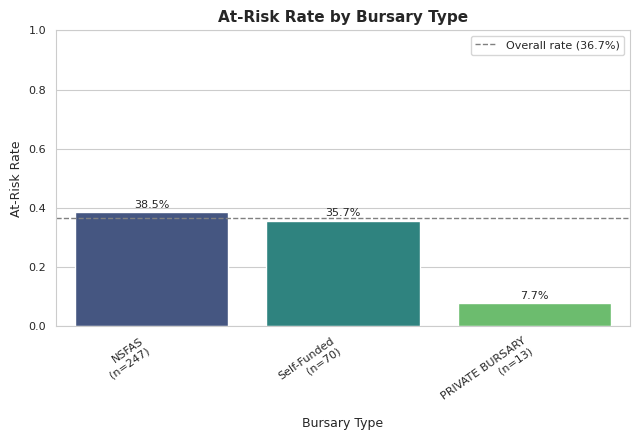

In [ ]:
# At-Risk Rate by Bursary Type
plot_rate_by('Bursary Type', title='At-Risk Rate by Bursary Type')

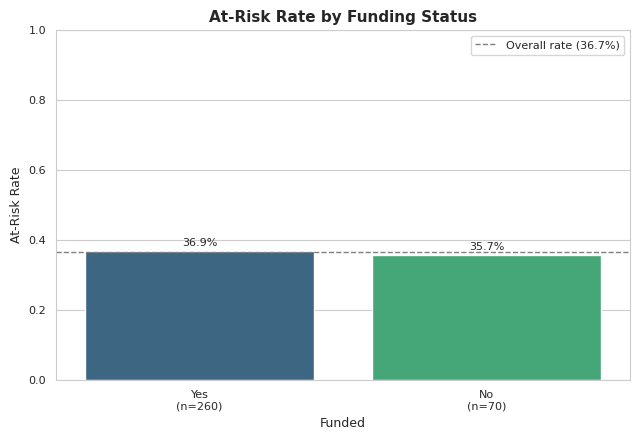

In [ ]:
# At-Risk Rate by Funded
plot_rate_by('Funded', title='At-Risk Rate by Funding Status')

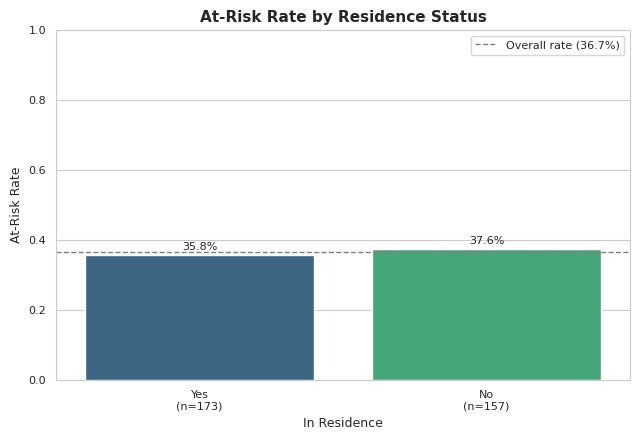

In [ ]:
# At-Risk Rate by In Residence
plot_rate_by('In Residence', title='At-Risk Rate by Residence Status')

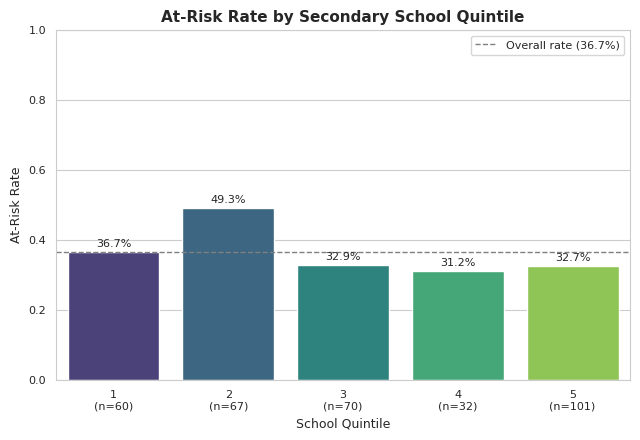

In [ ]:
# At-Risk Rate by School Quintile
plot_rate_by('School Quintile', title='At-Risk Rate by Secondary School Quintile')

/tmp/ipykernel_1077/2597614742.py:132: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = df.groupby(col)[target].agg(['mean', 'size']).reindex(order)


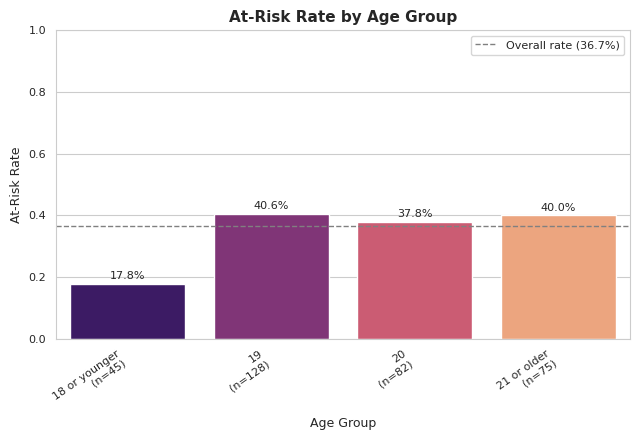

In [ ]:
# At-Risk Rate by Age Group
plot_rate_by('Age Group', palette='magma', title='At-Risk Rate by Age Group')

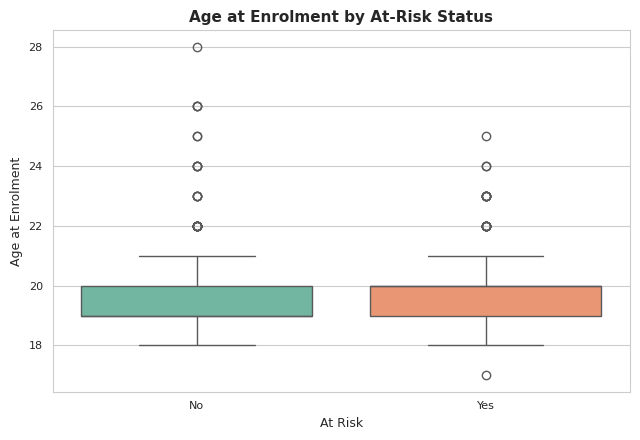

In [ ]:
# Age at Enrolment by At-Risk status (boxplot)
plot_box_by('At Risk', y='Age at Enrolment', title='Age at Enrolment by At-Risk Status')

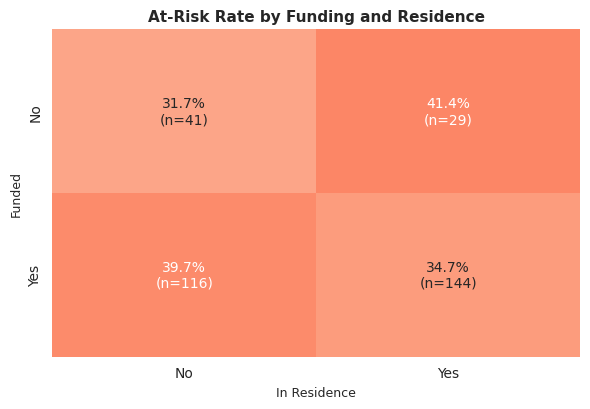

In [ ]:
# Funding and residence together: at-risk rate (%) with group size
rate = df1.pivot_table(index='Funded', columns='In Residence', values='At_Risk_Numeric', aggfunc='mean') * 100
size = df1.pivot_table(index='Funded', columns='In Residence', values='At_Risk_Numeric', aggfunc='size')
annot = rate.round(1).astype(str) + '%\n(n=' + size.astype('Int64').astype(str) + ')'

plt.figure(figsize=(6, 4.2))
sns.heatmap(rate, annot=annot, fmt='', cmap='Reds', cbar=False, vmin=0, vmax=100)
plt.title('At-Risk Rate by Funding and Residence', fontsize=11, fontweight='bold')
plt.xlabel('In Residence', fontsize=9)
plt.ylabel('Funded', fontsize=9)
plt.tight_layout()
plt.show()

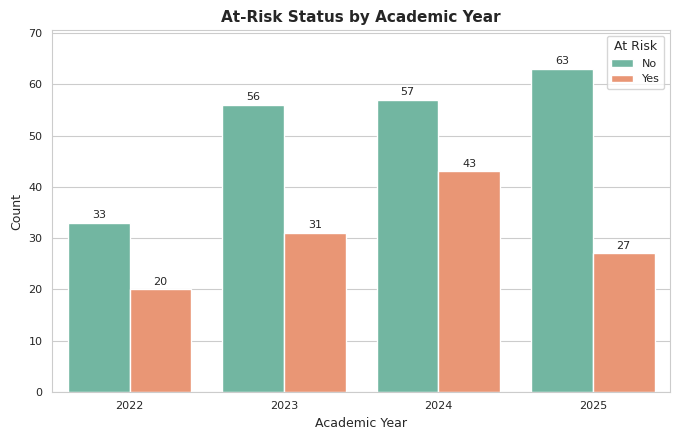

In [ ]:
# At-Risk status by Academic Year (counts)
plot_grouped_counts('Academic Year', 'At Risk', palette='Set2',
                    title='At-Risk Status by Academic Year', legend_title='At Risk')

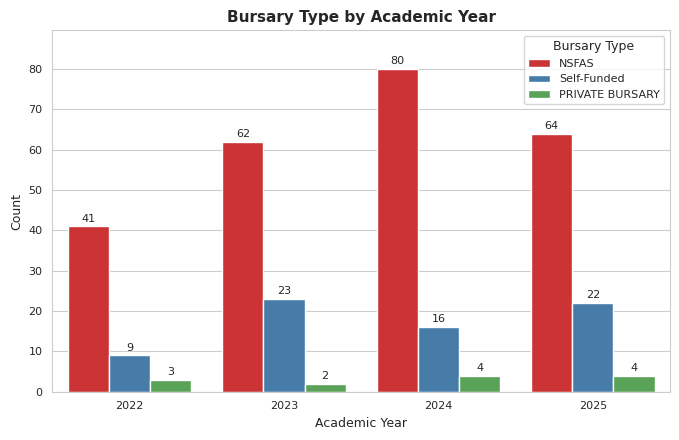

In [ ]:
# Bursary Type by Academic Year (counts): has the funding mix changed over the years?
plot_grouped_counts('Academic Year', 'Bursary Type', palette='Set1',
                    title='Bursary Type by Academic Year', legend_title='Bursary Type')

## Test associations

In [ ]:
def holm_adjust(p_values):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p_values, dtype=float)
    m = len(p)
    adjusted = np.empty(m)
    running_max = 0.0
    for rank, idx in enumerate(np.argsort(p)):
        running_max = max(running_max, (m - rank) * p[idx])
        adjusted[idx] = min(1.0, running_max)
    return adjusted

# Precompute all p-values first to maintain the correct Holm-Bonferroni multi-testing correction
target = 'At_Risk_Numeric'
cat_cols = ['Academic Year', 'Gender', 'Home Language', 'Ethnic Group', 'Previous Activity', 'Matric Type',
            'Bursary Type', 'Funded', 'In Residence', 'School Quintile', 'Age Group']
num_cols = ['Age at Enrolment']
all_cols = cat_cols + num_cols

raw_results = []
for col in cat_cols:
    contingency_table = pd.crosstab(df1[col], df1[target])
    if contingency_table.shape[0] < 2:
        p_val = np.nan
    else:
        _, p_val, _, _ = stats.chi2_contingency(contingency_table)
    raw_results.append({'Feature': col, 'p_value_raw': p_val})

for col in num_cols:
    group_yes = df1.loc[df1[target] == 1, col].dropna()
    group_no = df1.loc[df1[target] == 0, col].dropna()
    _, p_val = stats.mannwhitneyu(group_yes, group_no, alternative='two-sided')
    raw_results.append({'Feature': col, 'p_value_raw': p_val})

p_df = pd.DataFrame(raw_results)
p_df['p_value_corrected'] = holm_adjust(p_df['p_value_raw'])
corrected_p_dict = dict(zip(p_df['Feature'], p_df['p_value_corrected']))


def test_significance(col):
    """Perform and display the statistical test for a single variable against At Risk vertically"""
    if col not in df1.columns:
        print(f"Column '{col}' not found in the dataset.")
        return

    results = []
    corrected_p = corrected_p_dict.get(col, np.nan)

    if col in cat_cols:
        contingency_table = pd.crosstab(df1[col], df1[target])
        if contingency_table.shape[0] < 2:
            print(f"Not enough categories in '{col}' to run test.")
            return

        chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)
        n = contingency_table.sum().sum()
        min_dim = min(contingency_table.shape) - 1
        cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0

        results.append({
            'Feature': col,
            'Type': 'Categorical',
            'Test': 'Chi-Square',
            'Statistic': chi2,
            'p-value (Raw)': p_val,
            'p-value (Corrected)': corrected_p,
            "Effect Size (Cramer's V)": cramers_v,
            'Expected count < 5 (cells)': int((expected < 5).sum()),
            'Significant (a=0.05)': corrected_p < 0.05 if not pd.isna(corrected_p) else False
        })

    elif col in num_cols:
        group_yes = df1.loc[df1[target] == 1, col].dropna()
        group_no = df1.loc[df1[target] == 0, col].dropna()
        u_stat, p_val = stats.mannwhitneyu(group_yes, group_no, alternative='two-sided')
        rank_biserial = 1 - (2 * u_stat) / (len(group_yes) * len(group_no))

        results.append({
            'Feature': col,
            'Type': 'Numerical',
            'Test': 'Mann-Whitney U',
            'Statistic': u_stat,
            'p-value (Raw)': p_val,
            'p-value (Corrected)': corrected_p,
            "Effect Size (Rank-biserial)": abs(rank_biserial),
            'Expected count < 5 (cells)': np.nan,
            'Significant (a=0.05)': corrected_p < 0.05 if not pd.isna(corrected_p) else False
        })
    else:
        print(f"'{col}' is not configured in cat_cols or num_cols.")
        return

    single_df = pd.DataFrame(results)
    print(f"=== Association Test: {col} vs At Risk ===")
    # Transpose the DataFrame to display features and values vertically
    display(single_df.round(4).T)

# Displaying one example to show it works
test_significance('Academic Year')

=== Association Test: Academic Year vs At Risk ===


,0
Feature,Academic Year
Type,Categorical
Test,Chi-Square
Statistic,3.5159
p-value (Raw),0.3187
p-value (Corrected),1.0
Effect Size (Cramer's V),0.1032
Expected count < 5 (cells),0
Significant (a=0.05),False


In [ ]:
test_significance('Gender')

=== Association Test: Gender vs At Risk ===


,0
Feature,Gender
Type,Categorical
Test,Chi-Square
Statistic,0.1184
p-value (Raw),0.7308
p-value (Corrected),1.0
Effect Size (Cramer's V),0.0189
Expected count < 5 (cells),0
Significant (a=0.05),False


In [ ]:
test_significance('Home Language')

=== Association Test: Home Language vs At Risk ===


,0
Feature,Home Language
Type,Categorical
Test,Chi-Square
Statistic,8.086
p-value (Raw),0.6204
p-value (Corrected),1.0
Effect Size (Cramer's V),0.1565
Expected count < 5 (cells),7
Significant (a=0.05),False


In [ ]:
test_significance('Ethnic Group')

=== Association Test: Ethnic Group vs At Risk ===


,0
Feature,Ethnic Group
Type,Categorical
Test,Chi-Square
Statistic,1.6904
p-value (Raw),0.6391
p-value (Corrected),1.0
Effect Size (Cramer's V),0.0716
Expected count < 5 (cells),4
Significant (a=0.05),False


In [ ]:
test_significance('Previous Activity')

=== Association Test: Previous Activity vs At Risk ===


,0
Feature,Previous Activity
Type,Categorical
Test,Chi-Square
Statistic,7.6286
p-value (Raw),0.2666
p-value (Corrected),1.0
Effect Size (Cramer's V),0.152
Expected count < 5 (cells),7
Significant (a=0.05),False


In [ ]:
test_significance('Funded')

=== Association Test: Funded vs At Risk ===


,0
Feature,Funded
Type,Categorical
Test,Chi-Square
Statistic,0.0022
p-value (Raw),0.9629
p-value (Corrected),1.0
Effect Size (Cramer's V),0.0026
Expected count < 5 (cells),0
Significant (a=0.05),False


In [ ]:
test_significance('In Residence')

=== Association Test: In Residence vs At Risk ===


,0
Feature,In Residence
Type,Categorical
Test,Chi-Square
Statistic,0.0456
p-value (Raw),0.8309
p-value (Corrected),1.0
Effect Size (Cramer's V),0.0118
Expected count < 5 (cells),0
Significant (a=0.05),False


In [ ]:
test_significance('School Quintile')

=== Association Test: School Quintile vs At Risk ===


,0
Feature,School Quintile
Type,Categorical
Test,Chi-Square
Statistic,6.1064
p-value (Raw),0.1913
p-value (Corrected),1.0
Effect Size (Cramer's V),0.136
Expected count < 5 (cells),0
Significant (a=0.05),False


In [ ]:
test_significance('Age Group')

=== Association Test: Age Group vs At Risk ===


,0
Feature,Age Group
Type,Categorical
Test,Chi-Square
Statistic,8.1821
p-value (Raw),0.0424
p-value (Corrected),0.5087
Effect Size (Cramer's V),0.1575
Expected count < 5 (cells),0
Significant (a=0.05),False


## Subject performance

In [ ]:
# Summary statistics per subject
df1[subject_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Applied Mechanics,330.0,65.7,12.3,20.0,56.0,65.0,73.0,99.0
Computer Skills,330.0,70.3,12.4,2.0,65.0,71.0,78.0,96.0
Construction Materials,330.0,66.2,9.9,0.0,60.0,66.0,72.0,92.0
Engineering Chemistry,330.0,67.1,9.4,30.0,62.0,68.0,72.0,94.0
Engineering Drawing 1,330.0,61.3,12.1,10.0,54.0,61.0,69.0,89.0
Engineering Mathematics 1,330.0,61.2,12.5,18.0,53.0,62.0,69.0,97.0
Engineering Physics,330.0,58.1,8.0,18.0,53.0,58.0,63.0,82.0
Professional Communication,330.0,74.9,9.4,19.0,70.0,76.0,81.0,95.0
Surveying,330.0,62.6,13.3,12.0,54.0,63.0,72.0,94.0
Theory of Structures,330.0,56.2,15.0,0.0,50.0,56.0,65.0,94.0


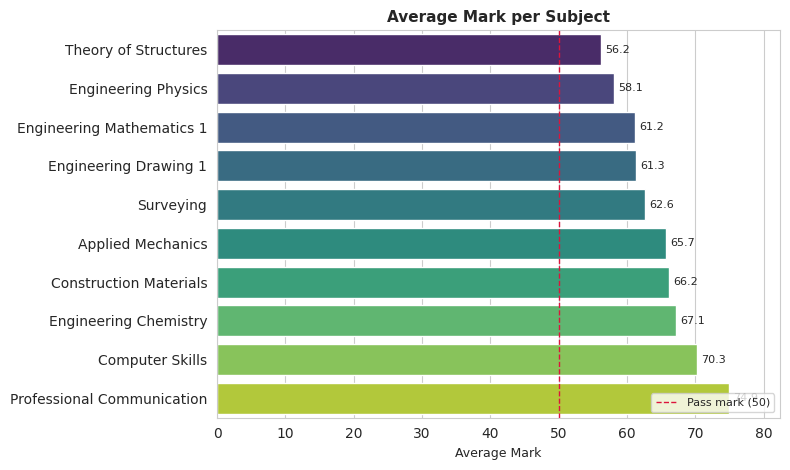

In [ ]:
# Average mark per subject
FAIL_MARK = 50
mean_marks = df1[subject_cols].mean().sort_values()

plt.figure(figsize=(8, 4.8))
ax = sns.barplot(x=mean_marks.values, y=mean_marks.index, hue=mean_marks.index, palette='viridis', legend=False)
for p in ax.patches:
    ax.annotate(f'{p.get_width():.1f}', (p.get_width(), p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=8, xytext=(3, 0), textcoords='offset points')
ax.axvline(FAIL_MARK, ls='--', color='crimson', lw=1, label=f'Pass mark ({FAIL_MARK})')
ax.margins(x=0.1)
plt.title('Average Mark per Subject', fontsize=11, fontweight='bold')
plt.xlabel('Average Mark', fontsize=9)
plt.ylabel('')
plt.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

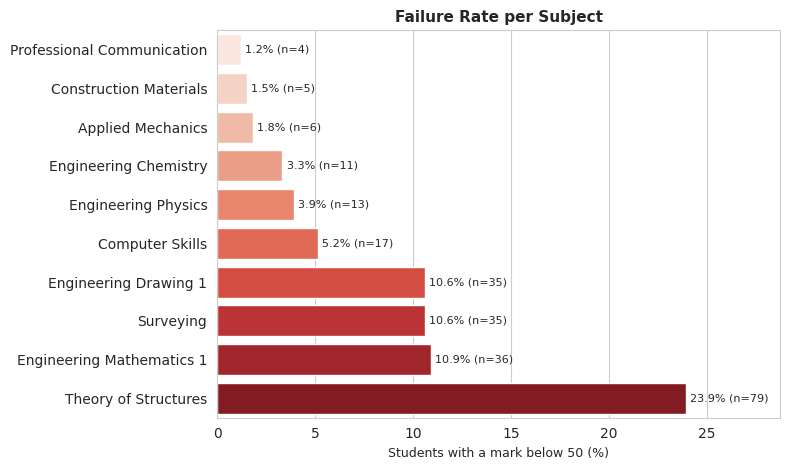

In [ ]:
# Failure rate per subject (% of students with a mark below 50)
fail_rate = ((df1[subject_cols] < FAIL_MARK).mean() * 100).sort_values()
fail_count = (df1[subject_cols] < FAIL_MARK).sum().reindex(fail_rate.index)

plt.figure(figsize=(8, 4.8))
ax = sns.barplot(x=fail_rate.values, y=fail_rate.index, hue=fail_rate.index, palette='Reds', legend=False)
for p, n_fail in zip(ax.patches, fail_count.values):
    ax.annotate(f'{p.get_width():.1f}% (n={int(n_fail)})', (p.get_width(), p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=8, xytext=(3, 0), textcoords='offset points')
ax.margins(x=0.2)
plt.title('Failure Rate per Subject', fontsize=11, fontweight='bold')
plt.xlabel('Students with a mark below 50 (%)', fontsize=9)
plt.ylabel('')
plt.tight_layout()
plt.show()

In [ ]:
# Number of subjects failed per student
plot_categorical('Subjects Failed', palette='Reds', title='Number of Subjects Failed per Student')

Column 'Subjects Failed' not found.


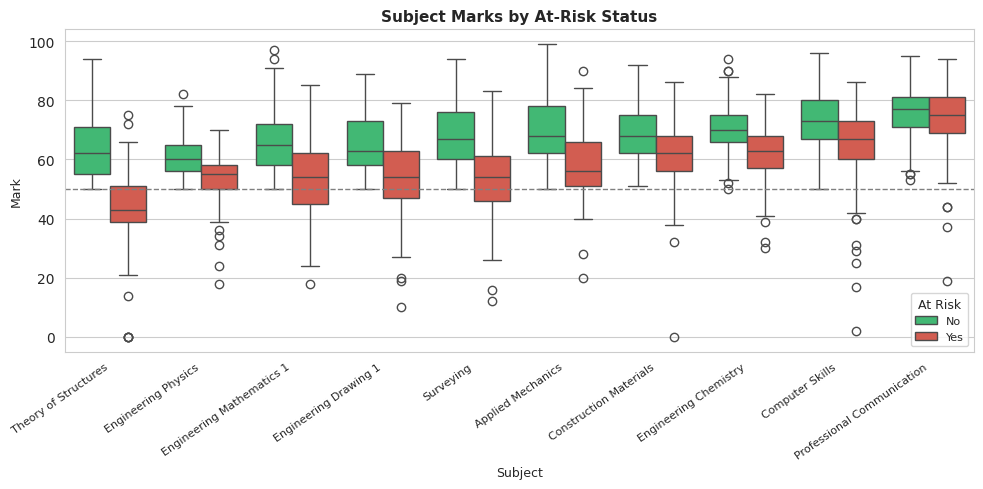

In [ ]:
# Subject marks by At-Risk status (boxplots)
marks_long = df1.melt(id_vars='At Risk', value_vars=subject_cols, var_name='Subject', value_name='Mark')
order = df1[subject_cols].mean().sort_values().index

plt.figure(figsize=(10, 5))
sns.boxplot(data=marks_long, x='Subject', y='Mark', hue='At Risk', order=order,
            hue_order=['No', 'Yes'], palette={'No': '#2ecc71', 'Yes': '#e74c3c'})
plt.axhline(FAIL_MARK, ls='--', color='grey', lw=1)
plt.title('Subject Marks by At-Risk Status', fontsize=11, fontweight='bold')
plt.xlabel('Subject', fontsize=9)
plt.ylabel('Mark', fontsize=9)
plt.xticks(rotation=35, ha='right', fontsize=8)
plt.legend(title='At Risk', fontsize=8, title_fontsize=9)
plt.tight_layout()
plt.show()

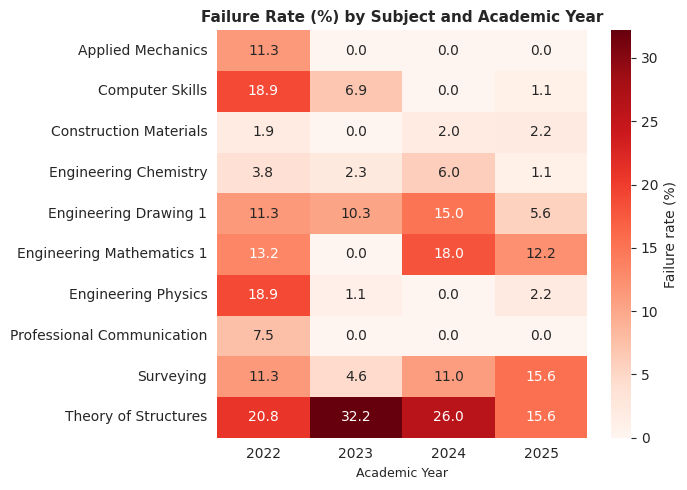

In [ ]:
# Failure rate (%) per subject and academic year
fail_by_year = (df1[subject_cols] < FAIL_MARK).groupby(df1['Academic Year']).mean().T * 100

plt.figure(figsize=(7, 5))
sns.heatmap(fail_by_year, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Failure rate (%)'})
plt.title('Failure Rate (%) by Subject and Academic Year', fontsize=11, fontweight='bold')
plt.xlabel('Academic Year', fontsize=9)
plt.ylabel('')
plt.tight_layout()
plt.show()

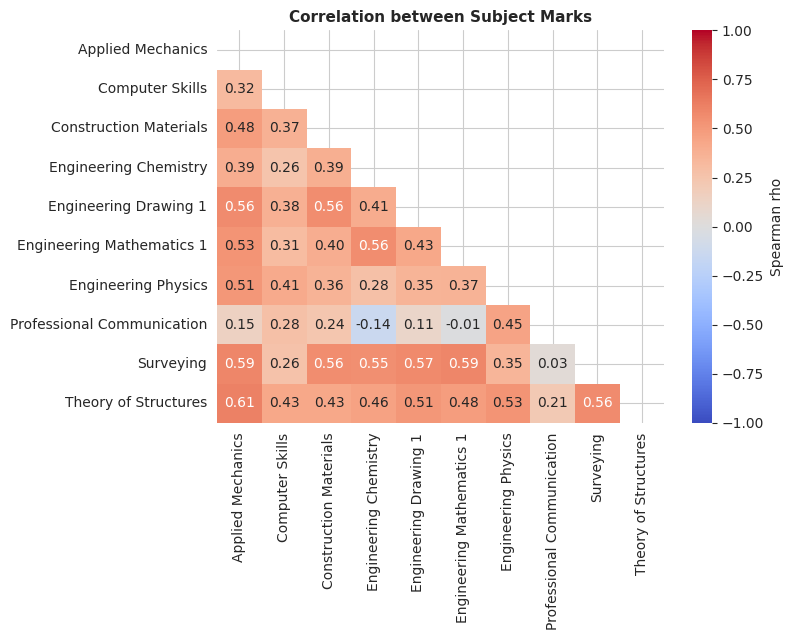

In [ ]:
# Correlation between subject marks (Spearman)
corr = df1[subject_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            cbar_kws={'label': 'Spearman rho'})
plt.title('Correlation between Subject Marks', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Count students who failed both Professional Communication and Computer Skills (mark < 50)
failed_both = df1[
    (df1['Professional Communication'] < 50) &
    (df1['Computer Skills'] < 50)
]

count_failed_both = len(failed_both)
print(f"Number of students who failed both Professional Communication and Computer Skills: {count_failed_both}")

Number of students who failed both Professional Communication and Computer Skills: 4


In [ ]:
# Calculate the number of students who scored below 50 for each subject
individual_failures = (df1[subject_cols] < 50).sum().sort_values(ascending=False).reset_index()
individual_failures.columns = ['Subject', 'Number of Failures']

n_total = len(df1)

# Calculate Failure Rate and Pass Rate
individual_failures['Failure Rate (%)'] = ((individual_failures['Number of Failures'] / n_total) * 100).round(2)
individual_failures['Pass Rate (%)'] = (100 - individual_failures['Failure Rate (%)']).round(2)

# Calculate 95% Confidence Interval for the Failure Rate
# Using the standard error of a proportion: SE = sqrt( p * (1 - p) / n )
p = individual_failures['Number of Failures'] / n_total
se = np.sqrt(p * (1 - p) / n_total)

# 95% Confidence Interval margin of error (z = 1.96)
margin_of_error = 1.96 * se

individual_failures['95% CI Lower (%)'] = ((p - margin_of_error).clip(0, 1) * 100).round(2)
individual_failures['95% CI Upper (%)'] = ((p + margin_of_error).clip(0, 1) * 100).round(2)

display(individual_failures)

,Subject,Number of Failures,Failure Rate (%),Pass Rate (%),95% CI Lower (%),95% CI Upper (%)
0,Theory of Structures,79,23.94,76.06,19.34,28.54
1,Engineering Mathematics 1,36,10.91,89.09,7.55,14.27
2,Surveying,35,10.61,89.39,7.28,13.93
3,Engineering Drawing 1,35,10.61,89.39,7.28,13.93
4,Computer Skills,17,5.15,94.85,2.77,7.54
5,Engineering Physics,13,3.94,96.06,1.84,6.04
6,Engineering Chemistry,11,3.33,96.67,1.40,5.27
7,Applied Mechanics,6,1.82,98.18,0.38,3.26
8,Construction Materials,5,1.52,98.48,0.20,2.83
9,Professional Communication,4,1.21,98.79,0.03,2.39


In [ ]:
# Calculate the number of subjects failed for each student
subject_failures_per_student = (df1[subject_cols] < 50).sum(axis=1)

# Filter for students who failed at least 1 subject
failures_filtered = subject_failures_per_student[subject_failures_per_student > 0]

# Count occurrences of each number of failed subjects
failure_counts = failures_filtered.value_counts()

# Reindex to ensure we have all 10 rows (1 to 10 subjects failed) filled with 0 where appropriate
full_index = list(range(1, 11))
failure_counts_full = failure_counts.reindex(full_index, fill_value=0)

# Create the final summary DataFrame
failures_summary = pd.DataFrame({
    'Number of Subjects Failed': failure_counts_full.index,
    'Number of Students': failure_counts_full.values,
    'Percentage of All Students (%)': ((failure_counts_full.values / len(df1)) * 100).round(2),
    'Percentage of At-Risk Students (%)': ((failure_counts_full.values / len(failures_filtered)) * 100).round(2)
})

display(failures_summary)

,Number of Subjects Failed,Number of Students,Percentage of All Students (%),Percentage of At-Risk Students (%)
0,1,69,20.91,57.02
1,2,22,6.67,18.18
2,3,13,3.94,10.74
3,4,8,2.42,6.61
4,5,5,1.52,4.13
5,6,1,0.30,0.83
6,7,1,0.30,0.83
7,8,0,0.00,0.00
8,9,1,0.30,0.83
9,10,1,0.30,0.83


In [ ]:
# Calculate summary metrics for each subject
metrics = []

for sub in subject_cols:
    # Students below 50%
    below_50 = (df1[sub] < 50).sum()

    # Students between 50% and 59% (inclusive)
    between_50_59 = df1[sub].between(50, 59).sum()

    # Mean and Median
    avg_mark = df1[sub].mean()
    med_mark = df1[sub].median()

    metrics.append({
        'Subject': sub,
        'Students < 50%': below_50,
        'Students 50%-59%': between_50_59,
        'Average Mark': round(avg_mark, 2),
        'Median Mark': round(med_mark, 2)
    })

# Create DataFrame
subject_summary_table = pd.DataFrame(metrics)
display(subject_summary_table)

,Subject,Students < 50%,Students 50%-59%,Average Mark,Median Mark
0,Applied Mechanics,6,107,65.72,65.0
1,Computer Skills,17,28,70.29,71.0
2,Construction Materials,5,72,66.18,66.0
3,Engineering Chemistry,11,48,67.10,68.0
4,Engineering Drawing 1,35,111,61.28,61.0
5,Engineering Mathematics 1,36,109,61.23,62.0
6,Engineering Physics,13,184,58.13,58.0
7,Professional Communication,4,19,74.89,76.0
8,Surveying,35,97,62.56,63.0
9,Theory of Structures,79,122,56.21,56.0


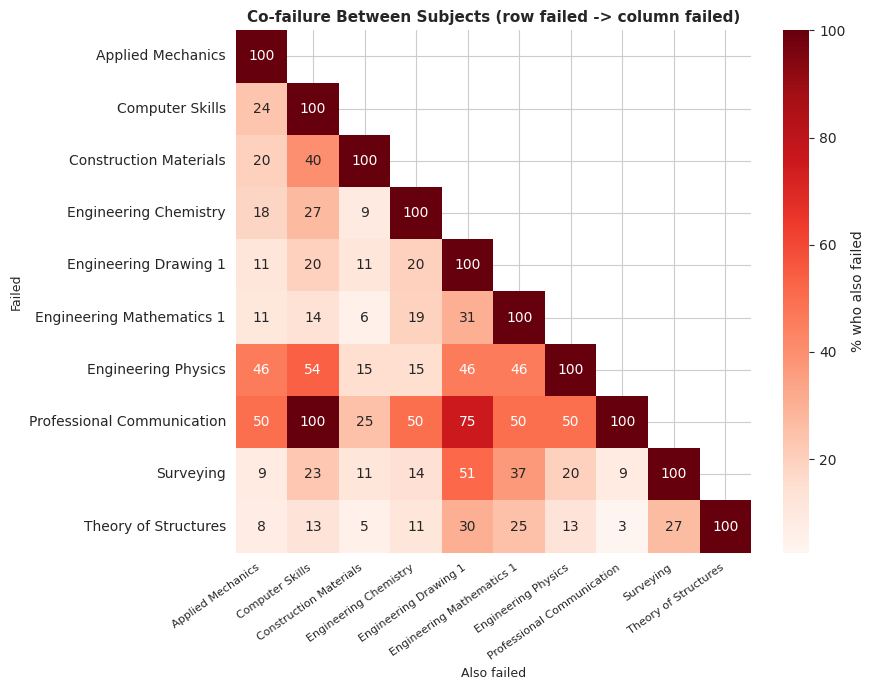

In [ ]:
# Co-failure: of the students who failed the subject in the ROW, what % also failed the subject in the COLUMN?
failed = (df1[subject_cols] < FAIL_MARK).astype(int)
co_fail = pd.DataFrame(index=subject_cols, columns=subject_cols, dtype=float)
for a in subject_cols:
    for b in subject_cols:
        co_fail.loc[a, b] = failed.loc[failed[a] == 1, b].mean() * 100 if failed[a].sum() > 0 else np.nan

# Mask the upper triangle (excluding the diagonal if desired, or including it)
# Using k=1 hides everything strictly above the main diagonal
mask = np.triu(np.ones_like(co_fail, dtype=bool), k=1)

plt.figure(figsize=(9, 7))
sns.heatmap(co_fail, mask=mask, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': '% who also failed'})
plt.title('Co-failure Between Subjects (row failed -> column failed)', fontsize=11, fontweight='bold')
plt.xlabel('Also failed', fontsize=9)
plt.ylabel('Failed', fontsize=9)
plt.xticks(rotation=35, ha='right', fontsize=8)
plt.tight_layout()
plt.show()

## Average mark (overall performance)

In [ ]:
# Engineering the overall academic performance metrics
df1['Average Mark'] = df1[subject_cols].mean(axis=1)
df1['Lowest Mark'] = df1[subject_cols].min(axis=1)
df1['Subjects Failed'] = (df1[subject_cols] < 50).sum(axis=1)

# Average Mark summary statistics
df1['Average Mark'].describe().round(2)

,Average Mark
count,330.00
mean,64.36
std,8.22
min,15.00
25%,60.02
50%,64.00
75%,68.90
max,87.90


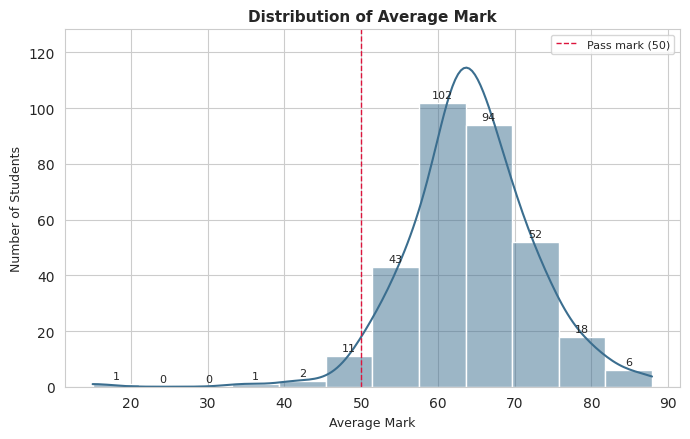

In [ ]:
# Distribution of Average Mark
plt.figure(figsize=(7, 4.5))
ax = sns.histplot(df1['Average Mark'], bins=12, kde=True, color='#3b6e8f')
add_bar_labels(ax)
ax.axvline(FAIL_MARK, ls='--', color='crimson', lw=1, label=f'Pass mark ({FAIL_MARK})')
plt.title('Distribution of Average Mark', fontsize=11, fontweight='bold')
plt.xlabel('Average Mark', fontsize=9)
plt.ylabel('Number of Students', fontsize=9)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

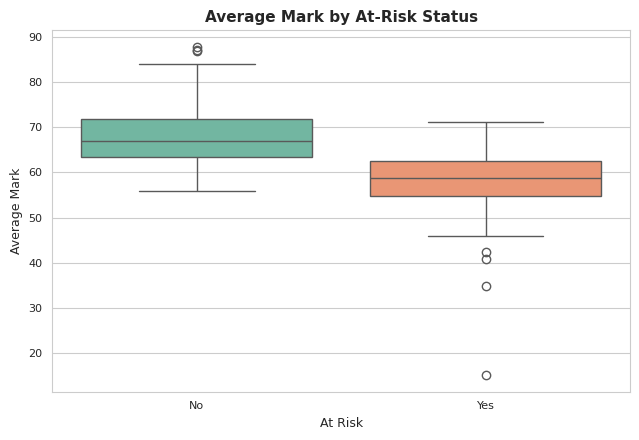

In [ ]:
# Average Mark by At-Risk status
plot_box_by('At Risk', title='Average Mark by At-Risk Status')

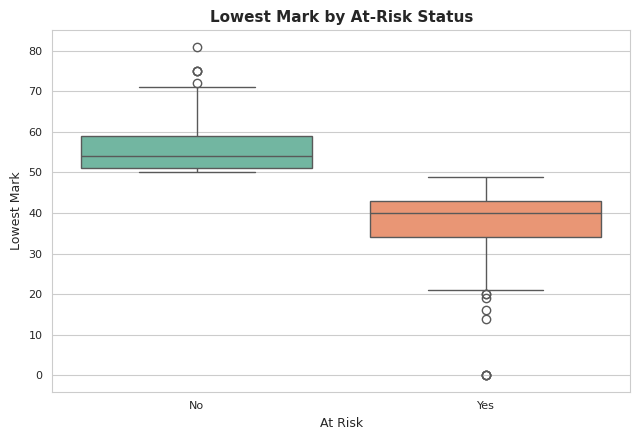

In [ ]:
# Lowest Mark by At-Risk status (the mark that decides whether a student is at risk)
plot_box_by('At Risk', y='Lowest Mark', title='Lowest Mark by At-Risk Status')

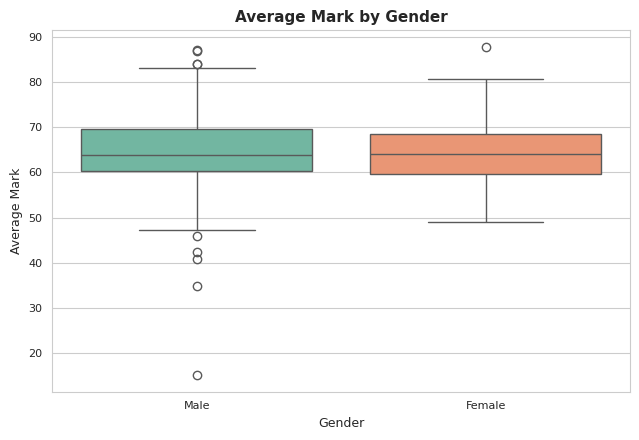

In [ ]:
# Average Mark by Gender
plot_box_by('Gender', title='Average Mark by Gender')

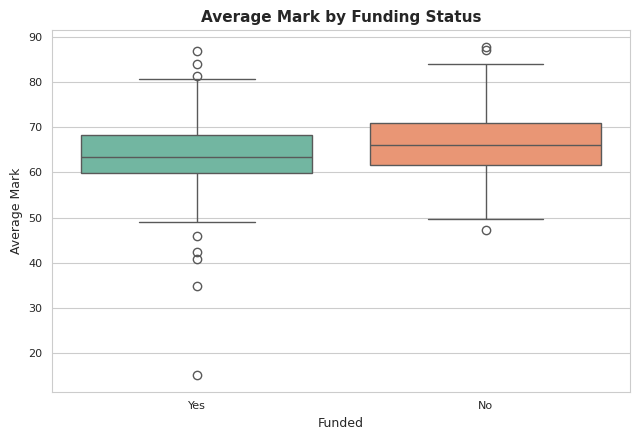

In [ ]:
# Average Mark by Funded
plot_box_by('Funded', title='Average Mark by Funding Status')

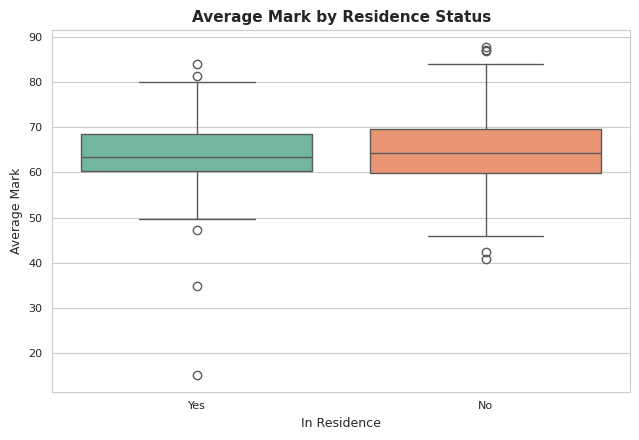

In [ ]:
# Average Mark by In Residence
plot_box_by('In Residence', title='Average Mark by Residence Status')

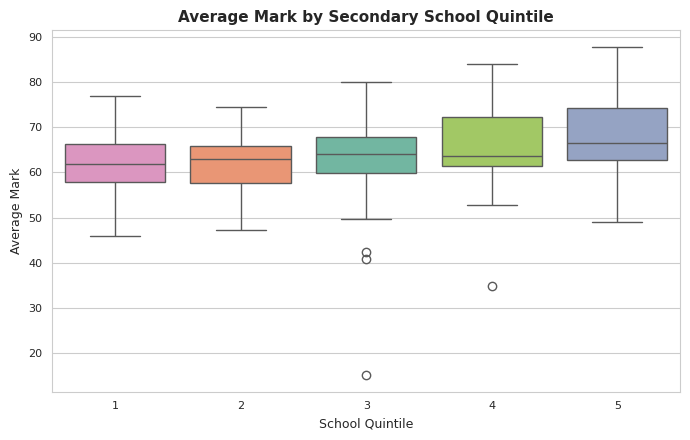

In [ ]:
# Average Mark by School Quintile
plot_box_by('School Quintile', title='Average Mark by Secondary School Quintile')

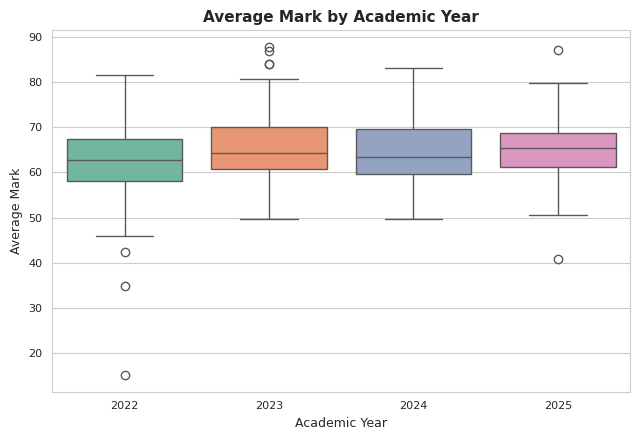

In [ ]:
# Average Mark by Academic Year
plot_box_by('Academic Year', title='Average Mark by Academic Year')

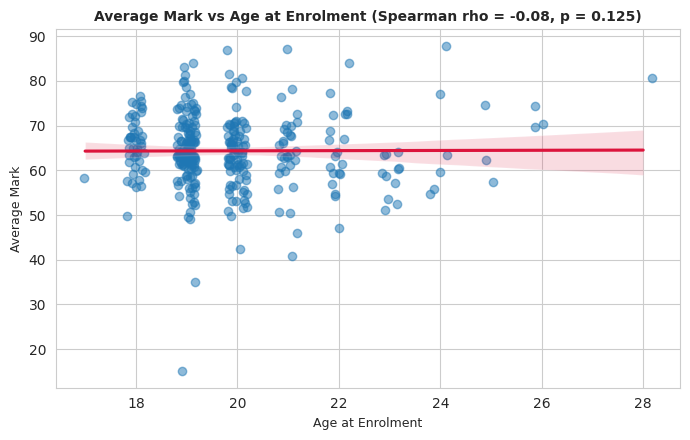

In [ ]:
# Average Mark vs Age at Enrolment
rho, p = stats.spearmanr(df1['Average Mark'], df1['Age at Enrolment'], nan_policy='omit')
plt.figure(figsize=(7, 4.5))
sns.regplot(data=df1, x='Age at Enrolment', y='Average Mark', x_jitter=0.2,
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'crimson'})
plt.title(f'Average Mark vs Age at Enrolment (Spearman rho = {rho:.2f}, p = {p:.3f})',
          fontsize=10, fontweight='bold')
plt.xlabel('Age at Enrolment', fontsize=9)
plt.ylabel('Average Mark', fontsize=9)
plt.tight_layout()
plt.show()

### Tests of Average Mark against student characteristics
Mann-Whitney U (2 groups), Kruskal-Wallis H (3+ groups) and Spearman correlation (numeric), with Holm-Bonferroni correction. Effect sizes: rank-biserial (Mann-Whitney), epsilon-squared (Kruskal-Wallis), |rho| (Spearman).

In [ ]:
mark_cat = ['Academic Year', 'Gender', 'Home Language', 'Ethnic Group', 'Previous Activity', 'Matric Type',
            'Bursary Type', 'Funded', 'In Residence', 'School Quintile', 'At Risk']
mark_num = ['Age at Enrolment']

mark_rows = []
for col in mark_cat:
    groups = [g['Average Mark'].dropna().values for _, g in df1.groupby(col) if g['Average Mark'].notna().sum() > 1]
    if len(groups) < 2:
        continue
    if len(groups) == 2:
        u, p_val = stats.mannwhitneyu(groups[0], groups[1], alternative='two-sided')
        eff = abs(1 - 2 * u / (len(groups[0]) * len(groups[1])))
        test, stat = 'Mann-Whitney U', u
    else:
        h_stat, p_val = stats.kruskal(*groups)
        n_tot = sum(len(g) for g in groups)
        eff = h_stat * (n_tot + 1) / (n_tot ** 2 - 1)
        test, stat = 'Kruskal-Wallis H', h_stat
    mark_rows.append({'Feature': col, 'Test': test, 'Statistic': stat, 'p-value': p_val, 'Effect Size': eff})

for col in mark_num:
    rho, p_val = stats.spearmanr(df1['Average Mark'], df1[col], nan_policy='omit')
    mark_rows.append({'Feature': col, 'Test': 'Spearman', 'Statistic': rho, 'p-value': p_val, 'Effect Size': abs(rho)})

mark_tests = pd.DataFrame(mark_rows)
mark_tests['p-value (Corrected)'] = holm_adjust(mark_tests['p-value'])
mark_tests['Significant (a=0.05)'] = mark_tests['p-value (Corrected)'] < 0.05
print("=== Statistical Tests: Average Mark vs Features ===")
display(mark_tests.sort_values('p-value (Corrected)').round(4))

=== Statistical Tests: Average Mark vs Features ===


,Feature,Test,Statistic,p-value,Effect Size,p-value (Corrected),Significant (a=0.05)
10,At Risk,Mann-Whitney U,22660.0000,0.0000,0.7921,0.0000,True
9,School Quintile,Kruskal-Wallis H,33.0097,0.0000,0.1003,0.0000,True
3,Ethnic Group,Kruskal-Wallis H,21.2317,0.0000,0.0647,0.0002,True
2,Home Language,Kruskal-Wallis H,37.3732,0.0000,0.1136,0.0004,True
6,Bursary Type,Kruskal-Wallis H,11.4860,0.0032,0.0349,0.0256,True
4,Previous Activity,Kruskal-Wallis H,14.4059,0.0132,0.0439,0.0926,False
7,Funded,Mann-Whitney U,10745.0000,0.0203,0.1808,0.1217,False
0,Academic Year,Kruskal-Wallis H,5.3922,0.1452,0.0164,0.6275,False
8,In Residence,Mann-Whitney U,14530.5000,0.2726,0.0700,0.6275,False
5,Matric Type,Kruskal-Wallis H,3.7618,0.1525,0.0115,0.6275,False
